# Dar_052 - Neutrons/resources: full native spectra, state, geometry and time

## Questions
- What do all selected days and all 11 native spectral channels add beyond the 74-day/five-channel screen?
- How do clocks, geometry/parameter flags, raw collection registers, zeros and native-word ceilings affect support?
- What does the full history show by month, quarter, four-month term, half-year, year, two-year window and calendar-season label?
- Do original sparse raw-spectrum summaries replay exactly, and what remains Unknown for local radiation/resources?

The complete selected LEND cohort is read file-by-file, not loaded as one huge array. Raw counts per reported collection second are **not calibrated flux, dose or qualified live exposure**. All-zero channels may reflect instrument state; they are not no neutrons, safe radiation or detected ice. South-of-80S ground track is not the instrument footprint or a candidate association. Native SCALT unit inconsistencies are reported, not silently changed.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'env_algo_task/EDA').is_dir())
sys.path.insert(0,str(root/'env_algo_task/EDA/Moon/Stage3_Requirements'))
from stage3_neutron_eda import execute

## Execute full selected cohort
A separate first/last-day sample validates the readers and resulting tables before the full run. Native labels/receipts and source identities are retained. Registers and geometry are support diagnostics, not detector-response qualification.

In [2]:
folder,findings=execute(sample=False)
display(findings)

LEND files read: 1 native frames: 86400


LEND files read: 101 native frames: 8726399


LEND files read: 201 native frames: 17293105


LEND files read: 301 native frames: 25933104


LEND files read: 401 native frames: 34573100


LEND files read: 501 native frames: 43213100


... (4 outputs left out)

LEND files read: 1001 native frames: 86246912


LEND files read: 1101 native frames: 94843288


{
  "subject": "neutrons_resources",
  "sample": false,
  "analysed_files": 1110,
  "native_frames": 95616238,
  "channels": [
    "STN1_SPECTRUM",
    "SETN_SPECTRUM",
    "STN2_SPECTRUM",
    "STN3_SPECTRUM",
    "CSETN1_SPECTRUM",
    "CSETN2_SPECTRUM",
    "CSETN3_SPECTRUM",
    "CSETN4_SPECTRUM",
    "SHEN1_SPECTRUM",
    "SHEN2_SPECTRUM",
    "SHEN3_SPECTRUM"
  ],
  "daily_rows": 24420,
  "first_utc": "2023-06-01 00:00:00+00:00",
  "last_utc": "2026-06-14 00:00:00+00:00",
  "tables": {
    "daily_context": 24420,
    "file_geometry_state": 1110,
    "track_geometry": 2220,
    "raw_channel_statistics": 24420,
    "monthly_spectral_bins": 13024,
    "zero_channel_summary": 22,
    "calendar_context": 1914,
    "matched_June_October_years": 88,
    "unit_holds": 1110,
    "field_metadata": 46,
    "crosscheck_Dar044": 7,
    "stage4_neutron_proposals": 6
  },
  "time_contract": "UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=J

{'subject': 'neutrons_resources',
 'sample': False,
 'analysed_files': 1110,
 'native_frames': 95616238,
 'channels': ['STN1_SPECTRUM',
  'SETN_SPECTRUM',
  'STN2_SPECTRUM',
  'STN3_SPECTRUM',
  'CSETN1_SPECTRUM',
  'CSETN2_SPECTRUM',
  'CSETN3_SPECTRUM',
  'CSETN4_SPECTRUM',
  'SHEN1_SPECTRUM',
  'SHEN2_SPECTRUM',
  'SHEN3_SPECTRUM'],
 'daily_rows': 24420,
 'first_utc': '2023-06-01 00:00:00+00:00',
 'last_utc': '2026-06-14 00:00:00+00:00',
 'tables': {'daily_context': 24420,
  'file_geometry_state': 1110,
  'track_geometry': 2220,
  'raw_channel_statistics': 24420,
  'monthly_spectral_bins': 13024,
  'zero_channel_summary': 22,
  'calendar_context': 1914,
  'matched_June_October_years': 88,
  'unit_holds': 1110,
  'field_metadata': 46,
  'crosscheck_Dar044': 7,
  'stage4_neutron_proposals': 6},
 'time_contract': 'UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=Jan-Apr/May-Aug/Sep-Dec; DJF/MAM/JJA/SON are calendar labels only, not 

## Native state, units and spectral support
The XML SCALT unit is not assumed to mean km. Separately reported lunar-fixed position-vector radius is not that altitude field. Clock ambiguity and out-of-day records are withheld, while instrument/response validity remains unresolved.

In [3]:
display(pd.read_csv(folder/'file_geometry_state.csv').head(10))
display(pd.read_csv(folder/'unit_holds.csv').head(10))
display(pd.read_csv(folder/'zero_channel_summary.csv'))
display(pd.read_csv(folder/'monthly_spectral_bins.csv').head(32))

,file,date,records,nominal_dated_records,geometry_parameter_supported,clock_geometry_nominal_supported,ambiguous_or_missing_clock_records,outside_or_missing_nominal_clock_records,pointing_missing,not_intersecting,parameter_changed_records,nonpositive_collection_records,maximum_native_collection_seconds,supported_collection_register_seconds_sum,scope
0,lend_rdr_rsci_20230601.dat,2023-06-01 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
1,lend_rdr_rsci_20230602.dat,2023-06-02 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
2,lend_rdr_rsci_20230603.dat,2023-06-03 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
3,lend_rdr_rsci_20230604.dat,2023-06-04 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
4,lend_rdr_rsci_20230605.dat,2023-06-05 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
5,lend_rdr_rsci_20230606.dat,2023-06-06 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
6,lend_rdr_rsci_20230607.dat,2023-06-07 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
7,lend_rdr_rsci_20230608.dat,2023-06-08 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
8,lend_rdr_rsci_20230609.dat,2023-06-09 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."
9,lend_rdr_rsci_20230610.dat,2023-06-10 00:00:00+00:00,86400,86400,86400,86400,0,0,0,0,0,0,1.0,86400.0,"reported register/time/geometry support, NOT d..."


,file,field,native_unit,hold
0,lend_rdr_rsci_20230601.dat,SCALT,8,unresolved unit; not used as km or silently co...
1,lend_rdr_rsci_20230602.dat,SCALT,8,unresolved unit; not used as km or silently co...
2,lend_rdr_rsci_20230603.dat,SCALT,8,unresolved unit; not used as km or silently co...
3,lend_rdr_rsci_20230604.dat,SCALT,8,unresolved unit; not used as km or silently co...
4,lend_rdr_rsci_20230605.dat,SCALT,8,unresolved unit; not used as km or silently co...
5,lend_rdr_rsci_20230606.dat,SCALT,8,unresolved unit; not used as km or silently co...
6,lend_rdr_rsci_20230607.dat,SCALT,8,unresolved unit; not used as km or silently co...
7,lend_rdr_rsci_20230608.dat,SCALT,8,unresolved unit; not used as km or silently co...
8,lend_rdr_rsci_20230609.dat,SCALT,8,unresolved unit; not used as km or silently co...
9,lend_rdr_rsci_20230610.dat,SCALT,8,unresolved unit; not used as km or silently co...


,series_id,recorded_dates,supported_dates,all_supported_values_zero_dates,longest_consecutive_observed_zero_dates,interpretation,science_response_qualified
0,LEND_raw_rate_all_track_CSETN1_SPECTRUM,1110,1110,7,4,raw channel state diagnostic; missing dates br...,False
1,LEND_raw_rate_all_track_CSETN2_SPECTRUM,1110,1110,826,21,raw channel state diagnostic; missing dates br...,False
2,LEND_raw_rate_all_track_CSETN3_SPECTRUM,1110,1110,8,3,raw channel state diagnostic; missing dates br...,False
3,LEND_raw_rate_all_track_CSETN4_SPECTRUM,1110,1110,8,2,raw channel state diagnostic; missing dates br...,False
4,LEND_raw_rate_all_track_SETN_SPECTRUM,1110,1110,767,15,raw channel state diagnostic; missing dates br...,False
5,LEND_raw_rate_all_track_SHEN1_SPECTRUM,1110,1110,11,5,raw channel state diagnostic; missing dates br...,False
6,LEND_raw_rate_all_track_SHEN2_SPECTRUM,1110,1110,13,6,raw channel state diagnostic; missing dates br...,False
7,LEND_raw_rate_all_track_SHEN3_SPECTRUM,1110,1110,11,5,raw channel state diagnostic; missing dates br...,False
8,LEND_raw_rate_all_track_STN1_SPECTRUM,1110,1110,703,14,raw channel state diagnostic; missing dates br...,False
9,LEND_raw_rate_all_track_STN2_SPECTRUM,1110,1110,933,38,raw channel state diagnostic; missing dates br...,False


,month,region,channel,native_bin_index,raw_bin_counts_sum,scope
0,2023-06,all_track,STN1_SPECTRUM,0,1,native bin index only; no calibrated energy/ef...
1,2023-06,all_track,STN1_SPECTRUM,1,2,native bin index only; no calibrated energy/ef...
2,2023-06,all_track,STN1_SPECTRUM,2,2,native bin index only; no calibrated energy/ef...
3,2023-06,all_track,STN1_SPECTRUM,3,0,native bin index only; no calibrated energy/ef...
4,2023-06,all_track,STN1_SPECTRUM,4,0,native bin index only; no calibrated energy/ef...
5,2023-06,all_track,STN1_SPECTRUM,5,1,native bin index only; no calibrated energy/ef...
6,2023-06,all_track,STN1_SPECTRUM,6,0,native bin index only; no calibrated energy/ef...
7,2023-06,all_track,STN1_SPECTRUM,7,0,native bin index only; no calibrated energy/ef...
8,2023-06,all_track,STN1_SPECTRUM,8,0,native bin index only; no calibrated energy/ef...
9,2023-06,all_track,STN1_SPECTRUM,9,0,native bin index only; no calibrated energy/ef...


## Calendar and geometry context
Full denominators preserve partial windows and gaps. Zero-state runs count consecutive observed dates, not physical event durations. Broad orbital selections do not provide candidate-specific resource abundance or crew dose.

period_kind
calendar_season    286
four_month_term    220
half_year          154
month              814
quarter            286
two_year            66
year                88
Name: rows, dtype: int64

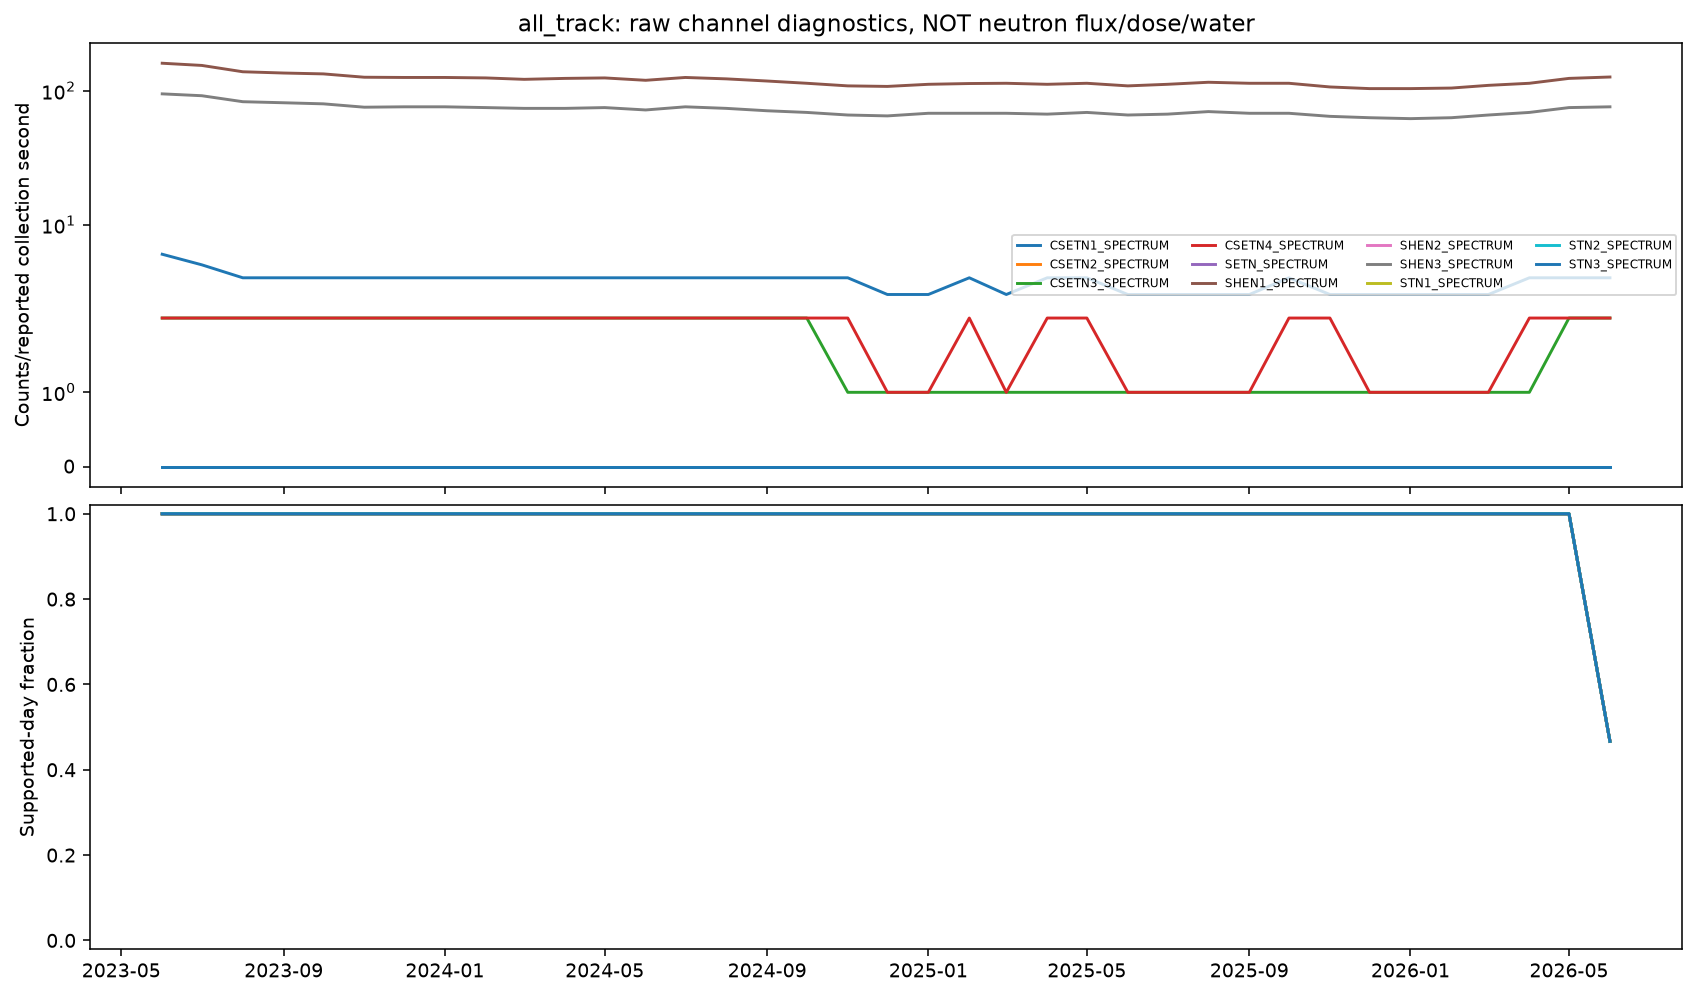

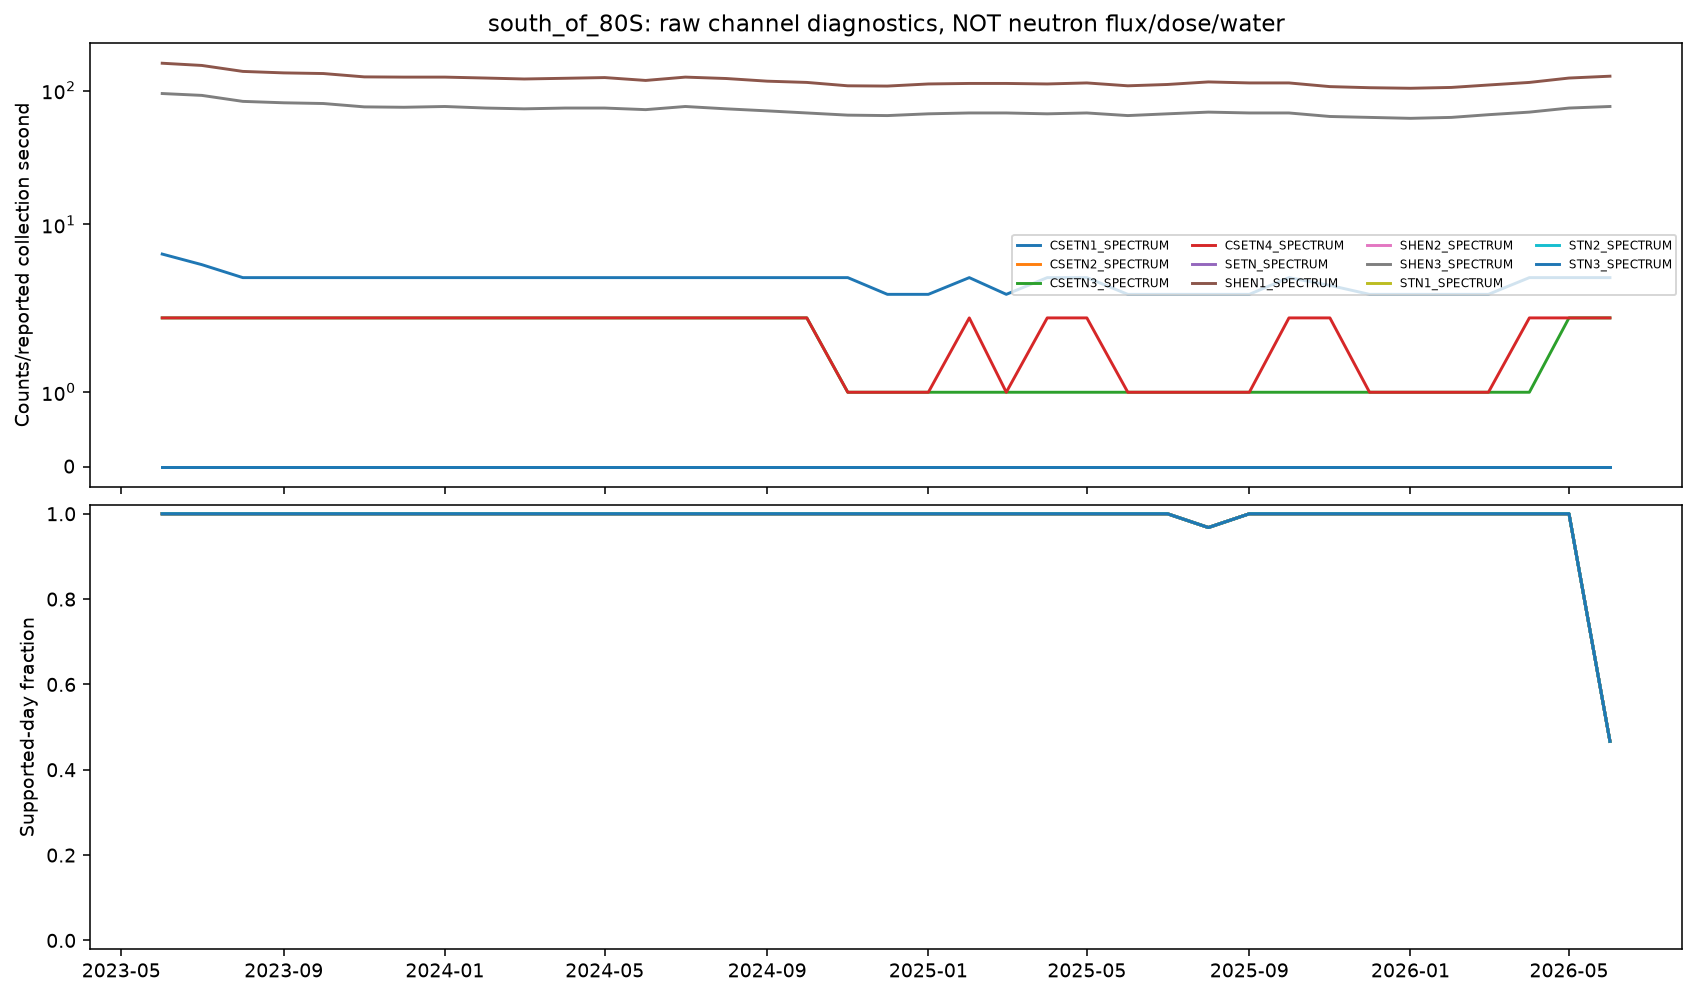

In [4]:
display(pd.read_csv(folder/'calendar_context.csv').groupby('period_kind').size().rename('rows'))
for region in ['all_track','south_of_80S']: display(Image(filename=str(folder/(region+'_channel_context.png'))))

## Old-cohort cross-check
Exactly replay the original geometry-only raw-spectrum contract on the old selected days/channels. New clock screening and six additional channels are distinct additions, not silent replacements of previous semantics.

In [5]:
display(pd.read_csv(folder/'crosscheck_Dar044.csv'))

,quantity,previous_rows,matched_rows,support_changed_rows,maximum_absolute_difference,scope
0,geometry_parameter_supported,740,740,0,0.0,original 74-file/five-channel geometry-only co...
1,valid,740,740,0,0.0,original 74-file/five-channel geometry-only co...
2,min,740,740,0,0.0,original 74-file/five-channel geometry-only co...
3,median,740,740,0,0.0,original 74-file/five-channel geometry-only co...
4,p95,740,740,0,0.0,original 74-file/five-channel geometry-only co...
5,max,740,740,0,0.0,original 74-file/five-channel geometry-only co...
6,nonzero_supported_records,740,740,0,0.0,original 74-file/five-channel geometry-only co...


## Proposed requirements and base conclusion
Raw spectral/state context improves evidence coverage, not calibrated resource or radiation adequacy. Essential neutron protection requires applicable local response/limits; resource supply becomes mandatory only for a mission explicitly dependent on extraction. Missing evidence remains Unknown; Stage 5 is unchanged.

In [6]:
display(pd.read_csv(folder/'stage4_neutron_proposals.csv')[['id','classification','title','current_outcome','decision_logic']])
print(json.dumps(findings,indent=2))
print('Completed run:',folder)

,id,classification,title,current_outcome,decision_logic
0,NE-G01,evidence_guard,Native spectra/state are not calibrated flux o...,Unknown,All-zero raw channels and spectral-bin sums do...
1,NE-G02,evidence_guard,Preserve raw collection-register and time support,Unknown,Counts per reported collection second are raw ...
2,NE-G03,evidence_guard,Units and detector footprint before altitude/s...,Unknown,Do not silently interpret the XML SCALT unit 8...
3,NE-H01,conditional_hard_constraint,Applicable neutron-radiation protection,Unknown,Failed if qualified applicable demand exceeds ...
4,NE-H02,conditional_hard_constraint,Resource capacity when the mission actually de...,Unknown,Only mandatory for a declared resource-depende...
5,NE-S01,conditional_soft_preference,Lower qualified resource/protection operationa...,Unknown,Do not reward raw low neutron counts or model ...


{
  "subject": "neutrons_resources",
  "sample": false,
  "analysed_files": 1110,
  "native_frames": 95616238,
  "channels": [
    "STN1_SPECTRUM",
    "SETN_SPECTRUM",
    "STN2_SPECTRUM",
    "STN3_SPECTRUM",
    "CSETN1_SPECTRUM",
    "CSETN2_SPECTRUM",
    "CSETN3_SPECTRUM",
    "CSETN4_SPECTRUM",
    "SHEN1_SPECTRUM",
    "SHEN2_SPECTRUM",
    "SHEN3_SPECTRUM"
  ],
  "daily_rows": 24420,
  "first_utc": "2023-06-01 00:00:00+00:00",
  "last_utc": "2026-06-14 00:00:00+00:00",
  "tables": {
    "daily_context": 24420,
    "file_geometry_state": 1110,
    "track_geometry": 2220,
    "raw_channel_statistics": 24420,
    "monthly_spectral_bins": 13024,
    "zero_channel_summary": 22,
    "calendar_context": 1914,
    "matched_June_October_years": 88,
    "unit_holds": 1110,
    "field_metadata": 46,
    "crosscheck_Dar044": 7,
    "stage4_neutron_proposals": 6
  },
  "time_contract": "UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=J